# GAUSSIAN annual portfolio research

**Research question.** How do the three portfolio risk objectives behave at the exact ERC expected return under this fitted model?

The market supplies one observed history. Forecasting sees that history only; true parameters and terminal state are reserved for the evaluator. Annual terminal asset returns describe one allocation held for 252 days. The original daily Gaussian notebook is preserved separately.

This recipe runs independently in the installed project environment. The default is a labelled smoke experiment; set `THESIS_PROFILE=pilot` before starting the kernel for the configured pilot counts. Source functions are reusable and directly linked below. Outputs report actual calculations, not assumed findings.

## 1. Reproducible specification

The 1000-observation pilot reference is provisional. Source-exact recovery lives in a separate research recipe; no history length is declared scientifically adequate without agreed criteria.

### Import the shared research machinery

Imports load definitions without running another notebook.

**Inputs:** installed package.  
**Created / outputs:** named functions.  
**Canonical implementation:** `thesis_portfolio.annual`.

In [1]:
# M4A.GAUSSIAN.SETUP.01 — Import the shared research machinery
# Inputs: installed package
# Created: named functions
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from thesis_portfolio.annual.config import PublicSpec, load_run_config, oracle_state, project_root, stream
from thesis_portfolio.annual.simulation import generate_history, simulate_conditional_paths, oracle_continue
from thesis_portfolio.annual.estimation import fit_market_model
from thesis_portfolio.annual.portfolio import annual_moments, freeze_portfolios, evaluate_portfolios
from thesis_portfolio.optimization import equal_risk_contribution, markowitz, cvar, risk_contributions
from thesis_portfolio.annual.diagnostics import mathematical_backstops, residual_diagnostics, parameter_comparison, recurrence_report
from thesis_portfolio.annual.experiment import execution_profile, begin_run, save_run
from thesis_portfolio.annual import visualization as plots


### Load the run configuration

Public fitting options are separated from the privileged oracle specification.

**Inputs:** project installation, profile.  
**Created / outputs:** root, cfg.  
**Canonical implementation:** `annual.config.load_run_config`.

In [2]:
# M4A.GAUSSIAN.SETUP.02 — Load the run configuration
# Inputs: project installation, profile
# Created: root, cfg
root = project_root(os.environ.get('THESIS_PROJECT_ROOT'))
cfg = execution_profile(load_run_config(root / 'configs/annual/pilot.yaml'), os.environ.get('THESIS_PROFILE', 'smoke'))
display({k:v for k,v in cfg.items() if k not in ('oracle','seed')})


{'name': 'm05_annual_pilot',
 'status': 'provisional_pilot',
 'history': {'observations': 1000,
  'recovery_candidates': [300, 600, 1200],
  'reference': 1000,
  'selection_status': 'provisional_reference_not_calibrated',
  'discarded_prefix': 0},
 'portfolio': {'horizon': 252,
  'policy': 'buy_and_hold',
  'target_policy': 'erc_fixed_return'},
 'simulation': {'optimization_paths': 10000,
  'evaluation_paths': 50000,
  'batch_size': 256,
  'retained_paths': 64},
 'risk': {'optimization_confidence': 0.95, 'reporting': [0.95, 0.99]},
 'fit': {'maxiter': 1000, 'fit_tolerance': 1e-09}}

### Open a new evidence record

A unique directory begins incomplete and becomes completed only after artifacts are saved.

**Inputs:** root, cfg.  
**Created / outputs:** run_path.  
**Canonical implementation:** `annual.experiment.begin_run`.

In [3]:
# M4A.GAUSSIAN.SETUP.03 — Open a new evidence record
# Inputs: root, cfg
# Created: run_path
oracle_family = 'gaussian'
run_path = begin_run(root, cfg, oracle_family)
display(run_path)


PosixPath('/Users/morty/Documents/ChatGPT/Thesis Under Prof. Rubtsov/results/m05-gaussian-baseline-provisional_pilot-20261127T163448-2a76f04c')

## 2. One observed timeline

The oracle is a synthetic market, not an investment decision-maker. No burn-in prefix is discarded. The first future day will continue from the final historical residual and variance.

### Construct the privileged oracle

Source dimensionless dynamics are preserved; the intercept is scaled to the provisional daily variance.

**Inputs:** private configuration.  
**Created / outputs:** oracle_parameters.  
**Canonical implementation:** `annual.config.oracle_state`.

In [4]:
# M4A.GAUSSIAN.HISTORY.01 — Construct the privileged oracle
# Inputs: private configuration
# Created: oracle_parameters
oracle_parameters = oracle_state(cfg, oracle_family)


### Generate one chronological history

Each row is one aligned observation across assets; latent state remains in the private record.

**Inputs:** oracle_parameters, history stream.  
**Created / outputs:** private_history.  
**Canonical implementation:** `annual.simulation.generate_history`.

In [5]:
# M4A.GAUSSIAN.HISTORY.02 — Generate one chronological history
# Inputs: oracle_parameters, history stream
# Created: private_history
private_history = generate_history(oracle_parameters, cfg['history']['observations'], stream(cfg['seed'], f'{oracle_family}/history'))


### Expose observations only

This is the complete information interface seen by the estimator.

**Inputs:** private_history observation export.  
**Created / outputs:** history.  
**Canonical implementation:** `annual.models.ObservedHistory`.

In [6]:
# M4A.GAUSSIAN.HISTORY.03 — Expose observations only
# Inputs: private_history observation export
# Created: history
history = private_history.observed
display(pd.DataFrame(history.returns, columns=history.assets).head())
print('Observed shape:', history.returns.shape)


,Asset_A,Asset_B,Asset_C,Asset_D,Asset_E
0,-0.002592,0.007894,0.010334,0.029087,0.015406
1,0.006278,-0.008426,0.013972,-0.020976,0.009533
2,-0.007444,0.002328,0.002306,-0.007864,0.006856
3,-0.002888,-0.006781,0.005468,-0.029059,-0.049708
4,-0.010351,0.000752,-0.026805,-0.027627,0.009680


Observed shape: (1000, 5)


## 3. Estimate the forecasting model

The conditional Gaussian likelihood sums log variance and squared standardized residuals. Variance initialization and numerical scaling use observations only. GARCH/GJR are fitted marginally by MLE; constant cross-asset correlation is then estimated from aligned standardized residuals. No oracle-assisted optimizer is present.

### Fit the observed history

All fitted means, variance coefficients, filtered states, and correlation come from observations.

**Inputs:** history, public family/options.  
**Created / outputs:** fitted.  
**Canonical implementation:** `annual.estimation.fit_market_model`.

In [7]:
# M4A.GAUSSIAN.ESTIMATION.01 — Fit the observed history
# Inputs: history, public family/options
# Created: fitted
public_spec = PublicSpec(oracle_family, **cfg['fit'])
fitted = fit_market_model(history, public_spec)


### Inspect parameter estimates

Boundary estimates are retained and flagged; source truth is not used to repair them.

**Inputs:** fitted.  
**Created / outputs:** parameter table and convergence diagnostics.  
**Canonical implementation:** `annual.estimation.FittedMarket`.

In [8]:
# M4A.GAUSSIAN.ESTIMATION.02 — Inspect parameter estimates
# Inputs: fitted
# Created: parameter table and convergence diagnostics
display(fitted.parameters)
display(pd.DataFrame(fitted.diagnostics))


,mu,omega,alpha,beta,gamma,persistence,long_run_variance
Asset_A,0.000262,0.000063,0.0,0.0,0.0,0.0,0.000063
Asset_B,0.000891,0.000140,0.0,0.0,0.0,0.0,0.000140
Asset_C,-0.000058,0.000265,0.0,0.0,0.0,0.0,0.000265
Asset_D,0.001323,0.000398,0.0,0.0,0.0,0.0,0.000398
Asset_E,0.000039,0.000549,0.0,0.0,0.0,0.0,0.000549


,success,method
0,True,sample moments
1,True,sample moments
2,True,sample moments
3,True,sample moments
4,True,sample moments


### Inspect estimated dependence

The forecast uses one constant correlation matrix estimated from standardized residuals. Conditional covariance still changes with volatility.

**Inputs:** fitted.  
**Created / outputs:** estimated correlation and eigenvalues.  
**Canonical implementation:** `annual.estimation.fit_market_model`.

In [9]:
# M4A.GAUSSIAN.ESTIMATION.03 — Inspect estimated dependence
# Inputs: fitted
# Created: estimated correlation and eigenvalues
display(pd.DataFrame(fitted.state.correlation, index=history.assets, columns=history.assets))
print(np.linalg.eigvalsh(fitted.state.correlation))


,Asset_A,Asset_B,Asset_C,Asset_D,Asset_E
Asset_A,1.000000,0.242236,0.194591,0.196966,0.254162
Asset_B,0.242236,1.000000,0.187046,0.232613,0.210928
Asset_C,0.194591,0.187046,1.000000,0.228465,0.207749
Asset_D,0.196966,0.232613,0.228465,1.000000,0.213430
Asset_E,0.254162,0.210928,0.207749,0.213430,1.000000


[0.7273456  0.76029603 0.80471618 0.83974438 1.86789781]


### Measure residual dependence

ACF and Ljung–Box references are descriptive. Fitted-parameter adjustments are not claimed, and no seed is discarded to obtain a favorable p-value.

**Inputs:** history, fitted.  
**Created / outputs:** residual_report.  
**Canonical implementation:** `annual.diagnostics.residual_diagnostics`.

In [10]:
# M4A.GAUSSIAN.DIAGNOSTICS.01 — Measure residual dependence
# Inputs: history, fitted
# Created: residual_report
residual_report = residual_diagnostics(history, fitted)
display(residual_report.drop_duplicates(["asset","series","squared"])[["asset","series","squared","reference_p"]])


,asset,series,squared,reference_p
0,Asset_A,centered_returns,False,0.020904
21,Asset_A,centered_returns,True,0.571194
42,Asset_A,standardized_residuals,False,0.020904
63,Asset_A,standardized_residuals,True,0.571194
84,Asset_B,centered_returns,False,0.586078
105,Asset_B,centered_returns,True,0.681359
126,Asset_B,standardized_residuals,False,0.586078
147,Asset_B,standardized_residuals,True,0.681359
168,Asset_C,centered_returns,False,0.009011
189,Asset_C,centered_returns,True,0.359480


### Plot volatility dependence

Compare squared observed returns with squared fitted standardized residuals.

**Inputs:** residual_report.  
**Created / outputs:** ACF figure.  
**Canonical implementation:** `annual.visualization.acf_figure`.

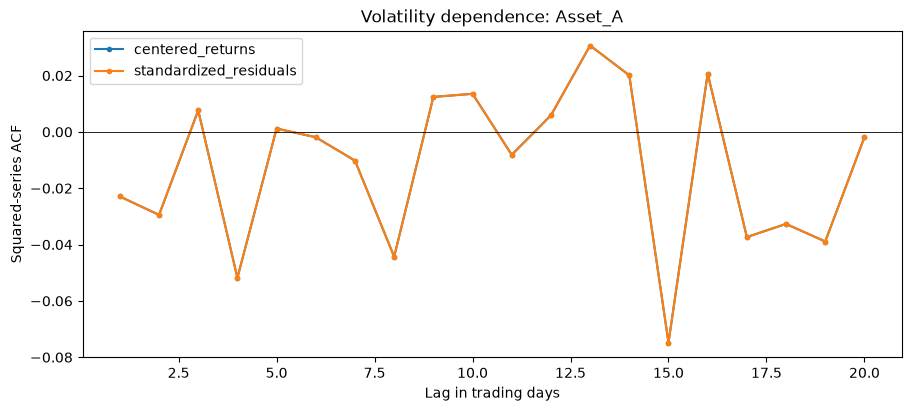

In [11]:
# M4A.GAUSSIAN.DIAGNOSTICS.02 — Plot volatility dependence
# Inputs: residual_report
# Created: ACF figure
acf_plot = plots.acf_figure(residual_report, history.assets[0])
plt.show()


## 4. Conditional annual futures

For each scenario and asset, $X_i=\prod_{t=1}^{252}(1+r_{t,i})-1$. Portfolio terminal return is $Xw$. Compounding weighted daily returns would instead impose daily rebalancing and is excluded.

### Check the formation-date state

The first future variance is computed from the last fitted residual and its associated variance, not reset to a long-run value.

**Inputs:** fitted endpoint.  
**Created / outputs:** first_variance.  
**Canonical implementation:** `annual.models.MarketState.next_variance`.

In [12]:
# M4A.GAUSSIAN.FORECAST.01 — Check the formation-date state
# Inputs: fitted endpoint
# Created: first_variance
first_variance = fitted.state.next_variance
display(pd.Series(first_variance, index=history.assets, name="First future daily variance"))


Asset_A    0.000063
Asset_B    0.000140
Asset_C    0.000265
Asset_D    0.000398
Asset_E    0.000549
Name: First future daily variance, dtype: float64

### Generate and aggregate annual futures

The batched simulator retains annual terminal scenarios and a small path subset. It stops on invalid simple returns rather than clipping or resampling.

**Inputs:** fitted state, fresh forecast stream.  
**Created / outputs:** forecast.  
**Canonical implementation:** `annual.simulation.simulate_conditional_paths`.

In [13]:
# M4A.GAUSSIAN.FORECAST.02 — Generate and aggregate annual futures
# Inputs: fitted state, fresh forecast stream
# Created: forecast
sim = cfg['simulation']
forecast = simulate_conditional_paths(fitted.state, 252, sim['optimization_paths'], stream(cfg['seed'], f'{oracle_family}/forecast/{oracle_family}'), batch_size=sim['batch_size'], retain=sim['retained_paths'])
print('Terminal scenarios:', forecast.terminal.shape)


Terminal scenarios: (10000, 5)


### Estimate common annual moments

All three strategies receive the same annual mean and covariance estimated from these fitted terminal scenarios.

**Inputs:** forecast.terminal.  
**Created / outputs:** annual_mean, annual_covariance.  
**Canonical implementation:** `annual.portfolio.annual_moments`.

In [14]:
# M4A.GAUSSIAN.FORECAST.03 — Estimate common annual moments
# Inputs: forecast.terminal
# Created: annual_mean, annual_covariance
annual_mean, annual_covariance = annual_moments(forecast.terminal)
display(pd.Series(annual_mean, index=history.assets, name="Fitted annual mean"))
display(pd.DataFrame(annual_covariance, index=history.assets, columns=history.assets))


Asset_A    0.066652
Asset_B    0.252483
Asset_C   -0.016171
Asset_D    0.398315
Asset_E    0.009185
Name: Fitted annual mean, dtype: float64

,Asset_A,Asset_B,Asset_C,Asset_D,Asset_E
Asset_A,0.018249,0.007316,0.006379,0.010228,0.012738
Asset_B,0.007316,0.055765,0.011032,0.024032,0.019222
Asset_C,0.006379,0.011032,0.067422,0.024952,0.019720
Asset_D,0.010228,0.024032,0.024952,0.203018,0.033627
Asset_E,0.012738,0.019222,0.019720,0.033627,0.154732


### Check tail-scenario mass

More future scenarios improve numerical precision; they do not add historical information. Smoke tail counts are deliberately small.

**Inputs:** forecast counts, confidence levels.  
**Created / outputs:** tail count table.  
**Canonical implementation:** `annual.simulation.FutureSample`.

In [15]:
# M4A.GAUSSIAN.FORECAST.04 — Check tail-scenario mass
# Inputs: forecast counts, confidence levels
# Created: tail count table
display(pd.DataFrame({'confidence':cfg['risk']['reporting'], 'forecast_tail_mass':[len(forecast.terminal)*(1-q) for q in cfg['risk']['reporting']]}))


,confidence,forecast_tail_mass
0,0.95,500.0
1,0.99,100.0


### Show conditional future paths

Quantiles in this fan come only from the explicitly labelled retained path subset. Full-sample tail metrics are computed separately.

**Inputs:** forecast.  
**Created / outputs:** fan_plot.  
**Canonical implementation:** `annual.visualization.fan_figure`.

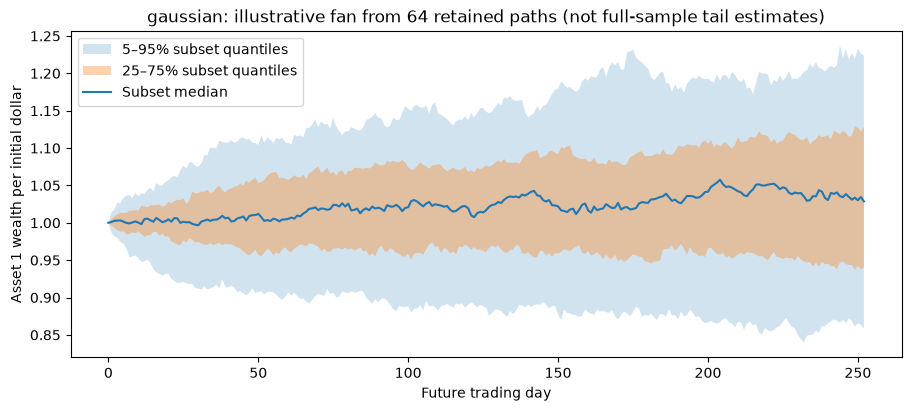

In [16]:
# M4A.GAUSSIAN.FORECAST.05 — Show conditional future paths
# Inputs: forecast
# Created: fan_plot
fan_plot = plots.fan_figure(forecast, oracle_family)
plt.show()


## 5. Exact ERC first, then equal expected return

With positive-definite covariance and standard long-only unit-budget constraints, the exact ERC allocation is unique. Its fitted annual mean is therefore the maximum over that singleton exact ERC set. It becomes the equality target for the other objectives; it is not a universal user-entered percentage.

### Solve exact annual ERC

The canonical convex risk-budgeting solver is reused without approximation.

**Inputs:** annual_covariance.  
**Created / outputs:** erc.  
**Canonical implementation:** `thesis_portfolio.optimization.equal_risk_contribution`.

In [17]:
# M4A.GAUSSIAN.ERC.01 — Solve exact annual ERC
# Inputs: annual_covariance
# Created: erc
erc = equal_risk_contribution(annual_covariance)
display(pd.Series(erc.weights, index=history.assets))


Asset_A    0.364797
Asset_B    0.206791
Asset_C    0.193419
Asset_D    0.110250
Asset_E    0.124743
dtype: float64

### Verify exact risk shares

Euler contributions must sum to portfolio volatility and each normalized share must equal 1/A.

**Inputs:** erc, annual_covariance.  
**Created / outputs:** risk_shares.  
**Canonical implementation:** `thesis_portfolio.optimization.risk_contributions`.

In [18]:
# M4A.GAUSSIAN.ERC.02 — Verify exact risk shares
# Inputs: erc, annual_covariance
# Created: risk_shares
contributions = risk_contributions(erc.weights, annual_covariance)
risk_shares = contributions / np.sqrt(erc.weights @ annual_covariance @ erc.weights)
np.testing.assert_allclose(risk_shares, 1/len(history.assets), atol=1e-8)
display(pd.Series(risk_shares, index=history.assets))


Asset_A    0.2
Asset_B    0.2
Asset_C    0.2
Asset_D    0.2
Asset_E    0.2
dtype: float64

### Freeze the model-specific fitted target

Equal fitted return controls the within-model strategy comparison; realized means need not match.

**Inputs:** annual_mean, erc.  
**Created / outputs:** r_star.  
**Canonical implementation:** `annual.portfolio.freeze_portfolios`.

In [19]:
# M4A.GAUSSIAN.TARGET.01 — Freeze the model-specific fitted target
# Inputs: annual_mean, erc
# Created: r_star
r_star = float(annual_mean @ erc.weights)
print(f"ERC-derived annual target: {r_star:.6%}")


ERC-derived annual target: 11.845756%


### Minimize variance at the ERC target

The target is an equality, including when it lies below the GMV expected return.

**Inputs:** annual moments, r_star.  
**Created / outputs:** mv.  
**Canonical implementation:** `thesis_portfolio.optimization.markowitz`.

In [20]:
# M4A.GAUSSIAN.MARKOWITZ.01 — Minimize variance at the ERC target
# Inputs: annual moments, r_star
# Created: mv
mv = markowitz(annual_mean, annual_covariance, target_return=r_star, target_constraint='equal')
display(mv.diagnostics)


{'solver': 'scipy.optimize.SLSQP',
 'success': True,
 'status': 0,
 'message': 'Optimization terminated successfully',
 'iterations': 9,
 'objective_name': 'variance',
 'objective_scale': 0.2030184893104386,
 'target_constraint': 'equal',
 'raw_minimum_weight': 6.712622303625522e-18,
 'roundoff_weights_zeroed': 0,
 'budget_error': 0.0,
 'minimum_weight': 6.712622303625522e-18,
 'estimated_return': 0.11845756011127428,
 'target_shortfall': 0.0,
 'target_error': 0.0}

### Minimize annual scenario CVaR

The sparse linear program uses one loss per simulated year and the identical annual mean in its return equality.

**Inputs:** forecast.terminal, annual_mean, r_star.  
**Created / outputs:** tail.  
**Canonical implementation:** `thesis_portfolio.optimization.cvar`.

In [21]:
# M4A.GAUSSIAN.CVAR.01 — Minimize annual scenario CVaR
# Inputs: forecast.terminal, annual_mean, r_star
# Created: tail
tail = cvar(forecast.terminal, confidence=cfg['risk']['optimization_confidence'], mean=annual_mean, target_return=r_star, target_constraint='equal')
display(tail.diagnostics)


{'solver': 'scipy.optimize.linprog.highs',
 'success': True,
 'status': 0,
 'message': 'Optimization terminated successfully. (HiGHS Status 7: Optimal)',
 'iterations': 2118,
 'objective_name': 'empirical_cvar_loss',
 'confidence': 0.95,
 'return_scale': 2.880294831536419,
 'eta': 0.07740125565767952,
 'scaled_inequality_violation': 1.3877787807814457e-17,
 'scenario_count': 10000,
 'target_constraint': 'equal',
 'raw_minimum_weight': 0.0,
 'roundoff_weights_zeroed': 0,
 'budget_error': 0.0,
 'minimum_weight': 0.0,
 'estimated_return': 0.11845756011127428,
 'target_shortfall': 0.0,
 'target_error': 0.0}

### Validate and freeze the comparison

Check exact ERC, all budget/return constraints, and that optimized in-sample objectives do not exceed feasible ERC objectives. Freeze forecast thresholds before evaluation.

**Inputs:** three solutions, forecast scenarios.  
**Created / outputs:** frozen.  
**Canonical implementation:** `annual.portfolio.freeze_portfolios`.

In [22]:
# M4A.GAUSSIAN.FREEZE.01 — Validate and freeze the comparison
# Inputs: three solutions, forecast scenarios
# Created: frozen
solutions = {'ERC':erc, 'Markowitz':mv, 'CVaR':tail}
frozen = freeze_portfolios(solutions, annual_mean, annual_covariance, forecast.terminal, cfg['risk']['reporting'])
display(frozen.constraints)
display(frozen.forecast_metrics)


,strategy,fitted_mean,target,return_residual,budget_residual,risk_share_error
0,ERC,0.118458,0.118458,0.0,0.0,1.142419e-13
1,Markowitz,0.118458,0.118458,0.0,0.0,4.030502e-01
2,CVaR,0.118458,0.118458,0.0,0.0,4.060006e-01


,strategy,confidence,mean,volatility,var,cvar
0,ERC,0.95,0.118458,0.148686,0.105156,0.149681
1,ERC,0.99,0.118458,0.148686,0.175670,0.209732
2,Markowitz,0.95,0.118458,0.126171,0.076993,0.117231
3,Markowitz,0.99,0.118458,0.126171,0.141175,0.173156
4,CVaR,0.95,0.118458,0.126204,0.077401,0.117168
5,CVaR,0.99,0.118458,0.126204,0.141548,0.173225


## 7. Held-out oracle evaluation

Only now are fresh oracle future shocks drawn. Every strategy and fitted family in this run receives the same terminal scenarios. These are independent conditional future years, not successive years to compound together.

### Draw shared conditional oracle futures

The evaluator continues from the true endpoint; no oracle input was used by the fitter or optimizer.

**Inputs:** private history, fresh evaluation stream, frozen allocations.  
**Created / outputs:** evaluation.  
**Canonical implementation:** `annual.simulation.oracle_continue`.

In [23]:
# M4A.GAUSSIAN.EVALUATION.01 — Draw shared conditional oracle futures
# Inputs: private history, fresh evaluation stream, frozen allocations
# Created: evaluation
evaluation = oracle_continue(private_history, 252, sim['evaluation_paths'], stream(cfg['seed'], f'{oracle_family}/evaluation'), batch_size=sim['batch_size'], retain=sim['retained_paths'])
print('Held-out annual scenarios:', evaluation.terminal.shape)


Held-out annual scenarios: (50000, 5)


### Measure annual risk and forecast exceptions

Exception uncertainty is conditional on this history and these fixed weights. It excludes estimation uncertainty across histories.

**Inputs:** frozen, evaluation.terminal.  
**Created / outputs:** metrics.  
**Canonical implementation:** `annual.portfolio.evaluate_portfolios`.

In [24]:
# M4A.GAUSSIAN.EVALUATION.02 — Measure annual risk and forecast exceptions
# Inputs: frozen, evaluation.terminal
# Created: metrics
metrics = evaluate_portfolios(frozen, evaluation.terminal)
display(metrics)


,strategy,confidence,fitted_target,oracle_mean,oracle_volatility,oracle_var,oracle_cvar,forecast_var,forecast_cvar,var_error,cvar_error,exceedances,exceedance_frequency,nominal_tail,exception_ci_low,exception_ci_high,tail_mass,concentration,paths,uncertainty_scope
0,ERC,0.95,0.118458,0.091093,0.146984,0.130600,0.174132,0.105156,0.149681,-0.025444,-0.024452,3871,0.07742,0.05,0.075092,0.079797,2500.0,0.240966,50000,conditional on this history and these frozen w...
1,ERC,0.99,0.118458,0.091093,0.146984,0.201268,0.230617,0.175670,0.209732,-0.025598,-0.020885,1006,0.02012,0.01,0.018907,0.021389,500.0,0.240966,50000,conditional on this history and these frozen w...
2,Markowitz,0.95,0.118458,0.065432,0.119819,0.120291,0.158976,0.076993,0.117231,-0.043298,-0.041746,5575,0.11150,0.05,0.108754,0.114291,2500.0,0.492129,50000,conditional on this history and these frozen w...
3,Markowitz,0.99,0.118458,0.065432,0.119819,0.183933,0.211950,0.141175,0.173156,-0.042758,-0.038794,1587,0.03174,0.01,0.030221,0.033314,500.0,0.492129,50000,conditional on this history and these frozen w...
4,CVaR,0.95,0.118458,0.065734,0.119945,0.120167,0.158859,0.077401,0.117168,-0.042766,-0.041690,5545,0.11090,0.05,0.108160,0.113685,2500.0,0.491474,50000,conditional on this history and these frozen w...
5,CVaR,0.99,0.118458,0.065734,0.119945,0.183775,0.211787,0.141548,0.173225,-0.042228,-0.038562,1563,0.03126,0.01,0.029752,0.032823,500.0,0.491474,50000,conditional on this history and these frozen w...


## 8. Evidence and interpretation

The following truth overlays belong to the researcher/evaluator layer and are produced after allocations are frozen. They are not additional fitting inputs.

### Check recurrence identities

A deterministic recursion failure is an implementation error; finite-sample parameter discrepancy is a separate research finding.

**Inputs:** private_history.  
**Created / outputs:** validation reports.  
**Canonical implementation:** `annual.diagnostics`.

In [25]:
# M4A.GAUSSIAN.VALIDATION.01 — Check recurrence identities
# Inputs: private_history
# Created: validation reports
display(mathematical_backstops())
display(recurrence_report(private_history))


{'garch_scalar': True,
 'constant_variance': True,
 'asymmetry': True,
 'gjr_nests_garch': True,
 'buy_hold': True,
 'not_daily_rebalanced': True}

{'maximum_recurrence_error': 0.0,
 'minimum_variance': 6.4e-05,
 'initialization': 'long-run variance, no discarded prefix'}

### Compare true and fitted parameters

The comparison shows finite-history estimation error without using truth to choose or repair the fitted model.

**Inputs:** private_history, fitted.  
**Created / outputs:** truth_comparison.  
**Canonical implementation:** `annual.diagnostics.parameter_comparison`.

In [26]:
# M4A.GAUSSIAN.VALIDATION.02 — Compare true and fitted parameters
# Inputs: private_history, fitted
# Created: truth_comparison
truth_comparison = parameter_comparison(private_history, fitted)
display(truth_comparison)


,mu,omega,alpha,beta,gamma,persistence,long_run_variance,true_mu,error_mu,true_omega,...,true_beta,error_beta,true_gamma,error_gamma,true_persistence,error_persistence,true_long_run_variance,error_long_run_variance,volatility_normalized_rmse,next_variance_error
Asset_A,0.000262,0.000063,0.0,0.0,0.0,0.0,0.000063,0.0002,0.000062,0.000064,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000064,-0.000001,0.009955,-0.000001
Asset_B,0.000891,0.000140,0.0,0.0,0.0,0.0,0.000140,0.0003,0.000591,0.000144,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000144,-0.000004,0.013634,-0.000004
Asset_C,-0.000058,0.000265,0.0,0.0,0.0,0.0,0.000265,0.0004,-0.000458,0.000256,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000256,0.000009,0.016501,0.000009
Asset_D,0.001323,0.000398,0.0,0.0,0.0,0.0,0.000398,0.0005,0.000823,0.000400,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000400,-0.000002,0.002289,-0.000002
Asset_E,0.000039,0.000549,0.0,0.0,0.0,0.0,0.000549,0.0006,-0.000561,0.000576,...,0.0,0.0,0.0,0.0,0.0,0.0,0.000576,-0.000027,0.023523,-0.000027


### Overlay fitted and oracle historical volatility

The evaluator can inspect where the filtered state tracks or misses the known synthetic state.

**Inputs:** history, fitted, private_history.  
**Created / outputs:** history_plot.  
**Canonical implementation:** `annual.visualization.history_figure`.

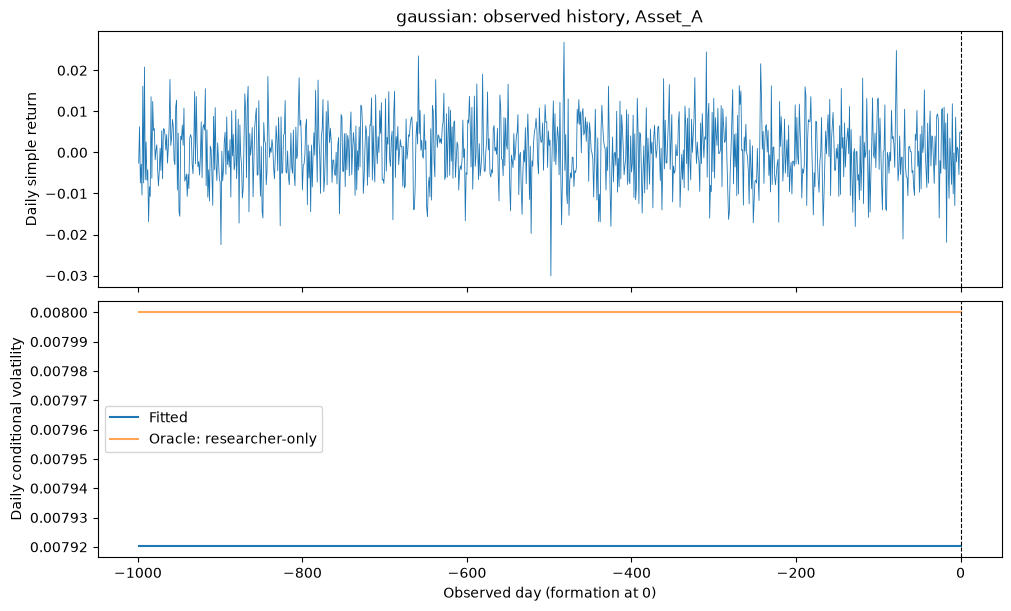

In [27]:
# M4A.GAUSSIAN.FIGURE.01 — Overlay fitted and oracle historical volatility
# Inputs: history, fitted, private_history
# Created: history_plot
history_plot = plots.history_figure(history, fitted, private_history)
plt.show()


### Show allocations and the annual frontier

The frontier is a diagnostic; it does not change the chosen ERC equality target.

**Inputs:** frozen, asset labels.  
**Created / outputs:** portfolio_plot.  
**Canonical implementation:** `annual.visualization.portfolio_figure`.

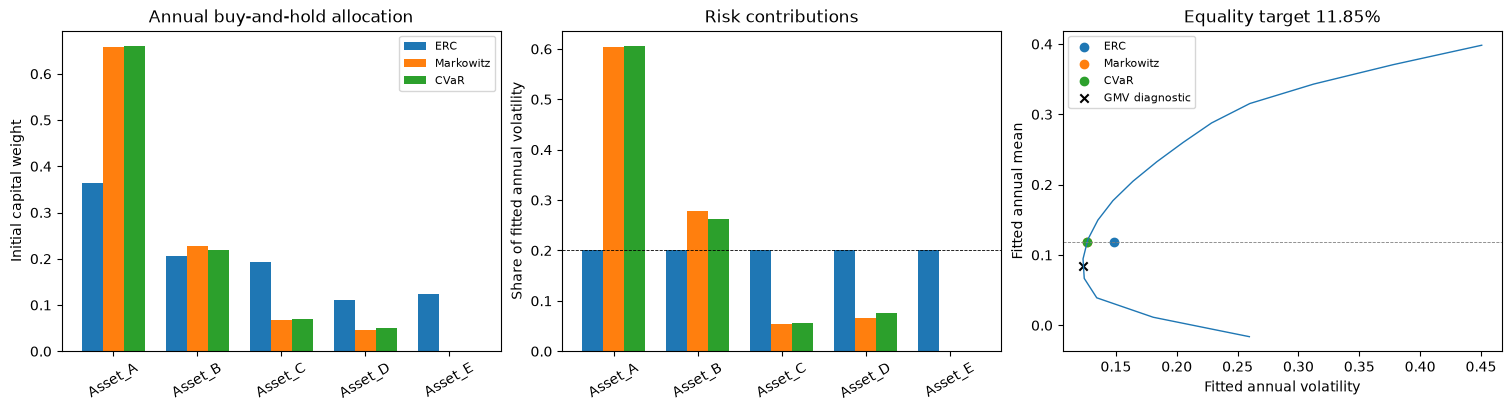

In [28]:
# M4A.GAUSSIAN.FIGURE.03 — Show allocations and the annual frontier
# Inputs: frozen, asset labels
# Created: portfolio_plot
portfolio_plot = plots.portfolio_figure(frozen, history.assets)
plt.show()


### Compare forecast and oracle annual losses

Annual loss distributions are empirical compounded outcomes, so daily Gaussian tail formulas are not used here.

**Inputs:** frozen, forecast, evaluation.  
**Created / outputs:** loss_plot.  
**Canonical implementation:** `annual.visualization.loss_figure`.

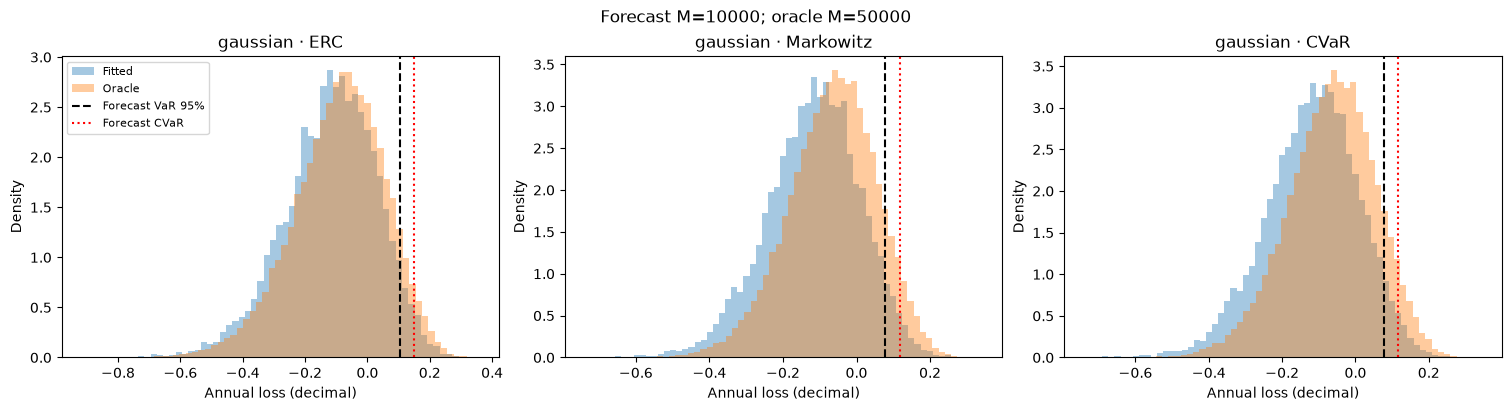

In [29]:
# M4A.GAUSSIAN.FIGURE.04 — Compare forecast and oracle annual losses
# Inputs: frozen, forecast, evaluation
# Created: loss_plot
loss_plot = plots.loss_figure(frozen, forecast, evaluation, oracle_family)
plt.show()


### Summarize this run without claiming a winner

Equal fitted means are a controlled input, whereas oracle means and risk measures are measured outcomes. Small smoke tail counts do not establish a scientific ranking.

**Inputs:** metrics, frozen.  
**Created / outputs:** observed summary.  
**Canonical implementation:** `annual.portfolio.evaluate_portfolios`.

In [30]:
# M4A.GAUSSIAN.INTERPRETATION.01 — Summarize this run without claiming a winner
# Inputs: metrics, frozen
# Created: observed summary
print(f'Largest fitted-return equality error: {abs(frozen.constraints.return_residual).max():.3g}')
print(f'Oracle mean range: {metrics.oracle_mean.min():.2%} to {metrics.oracle_mean.max():.2%}')
print('History selection:', cfg['history']['selection_status'])
print('This run does not certify calibration adequacy or an across-history strategy ranking.')


Largest fitted-return equality error: 0
Oracle mean range: 6.54% to 9.11%
History selection: provisional_reference_not_calibrated
This run does not certify calibration adequacy or an across-history strategy ranking.


### Save the reproducible evidence bundle

The manifest records actual counts, units, source hashes, solver diagnostics, scenario hashes, and provisional research status.

**Inputs:** validated outputs and figures.  
**Created / outputs:** manifest.  
**Canonical implementation:** `annual.experiment.save_run`.

In [31]:
# M4A.GAUSSIAN.SAVE.01 — Save the reproducible evidence bundle
# Inputs: validated outputs and figures
# Created: manifest
figures = {'history':history_plot, 'acf':acf_plot, 'fan':fan_plot, 'portfolios':portfolio_plot, 'losses':loss_plot}
manifest = save_run(root, run_path, cfg, private_history, {oracle_family:fitted}, {oracle_family:forecast}, {oracle_family:frozen}, evaluation, {oracle_family:metrics}, figures)
display(manifest['run_id'])
print(manifest['status'], manifest['scientific_status'])


'm05-gaussian-baseline-provisional_pilot-20261127T163448-2a76f04c'

completed provisional; calibration/count adequacy not certified


## Discussion

Use the saved table to distinguish estimated return equality from realized performance. Review the residual diagnostics, parameter errors and any boundary flags before interpretation. The next evidence is recovery across historical lengths and Monte Carlo convergence, followed by the registered stress cases. Rebalancing, copulas and the full cross-family grid remain outside this experiment.